# Phase 3: Time-Based Sales Analysis
**Integrated Retail Analytics for Store Optimization - Capstone**

**Objective:** Analyze sales trends over time, detect seasonal/holiday effects, and understand how store and department performance evolves week to week - setting up the demand forecasting phase.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
import warnings

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

In [11]:
# from google.colab import drive
# drive.mount('/content/drive')

## 1. Load data and build the overall weekly sales series

In [12]:
import pandas as pd

# Loading the correct dataset file from the directory
df = pd.read_csv("/content/drive/MyDrive/Integrated Retail Analytics for Store Optimization/Capston Anomaly Detection/Anomaly tagged data output/anomaly_tagged_data.csv", parse_dates=['Date'])

# Displaying the size / shape of the dataset
print(f"Dataset Shape: {df.shape} (Rows: {df.shape[0]}, Columns: {df.shape[1]})")

weekly_total = df.groupby('Date')['Weekly_Sales'].sum().sort_index()
print(f"Weeks: {len(weekly_total)}  |  Range: {weekly_total.index.min().date()} to {weekly_total.index.max().date()}")
weekly_total.head()

Dataset Shape: (421570, 26) (Rows: 421570, Columns: 26)
Weeks: 143  |  Range: 2010-02-05 to 2012-10-26


,Weekly_Sales
Date,
2010-02-05,49750740.50
2010-02-12,48336677.63
2010-02-19,48276993.78
2010-02-26,43968571.13
2010-03-05,46871470.30


In [13]:
import os

target_folder = "/content/drive/MyDrive/Integrated Retail Analytics for Store Optimization/Capston Anomaly Detection/Anomaly tagged data output"
if os.path.exists(target_folder):
    print(f"Files inside '{target_folder}':")
    for f in os.listdir(target_folder):
        print(f"- {f}")
else:
    print(f"Folder not found: {target_folder}")

Files inside '/content/drive/MyDrive/Integrated Retail Analytics for Store Optimization/Capston Anomaly Detection/Anomaly tagged data output':
- anomaly_tagged_data.csv


## 2. Smoothing with Rolling Averages
A single week's total is noisy - a 4-week rolling average smooths out short blips, while a 12-week rolling average shows the broader trend, the way a moving average on a stock chart filters out daily noise to reveal the real direction.

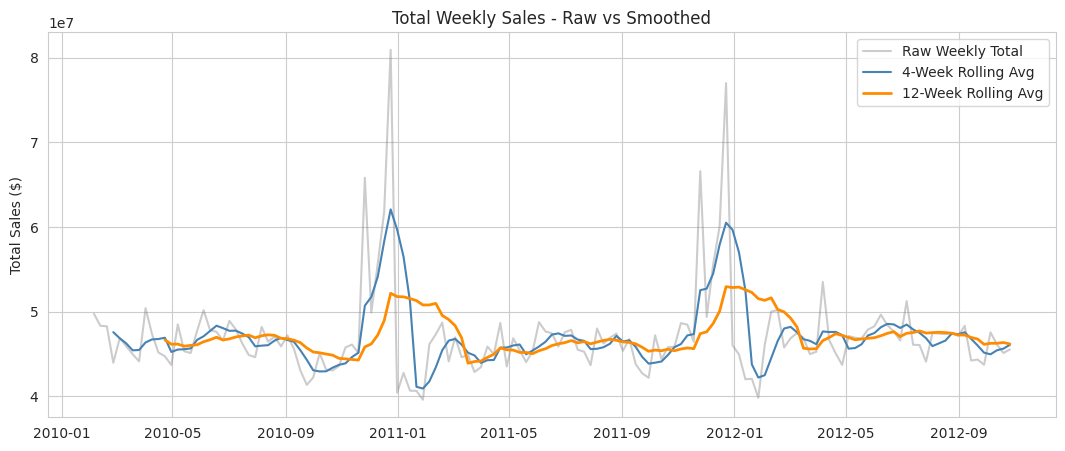

In [14]:
rolling_4 = weekly_total.rolling(4).mean()
rolling_12 = weekly_total.rolling(12).mean()

plt.figure(figsize=(13,5))
plt.plot(weekly_total.index, weekly_total.values, alpha=0.4, label='Raw Weekly Total', color='gray')
plt.plot(rolling_4.index, rolling_4.values, label='4-Week Rolling Avg', color='steelblue')
plt.plot(rolling_12.index, rolling_12.values, label='12-Week Rolling Avg', color='darkorange', linewidth=2)
plt.title('Total Weekly Sales - Raw vs Smoothed')
plt.ylabel('Total Sales ($)')
plt.legend()
plt.show()

**Insight:** the 12-week average confirms there's no strong long-term growth or decline across the 3 years - sales oscillate in a fairly stable band, with the 4-week average clearly picking up the sharp holiday-season bumps that the 12-week average smooths away.

## 3. Seasonal Decomposition
This splits the series into three layers:
- **Trend** - the slow-moving underlying direction
- **Seasonal** - the repeating yearly pattern (holidays, month effects)
- **Residual** - whatever's left over (noise / one-off events)

Weekly data with a yearly cycle needs a period of ~52 weeks.

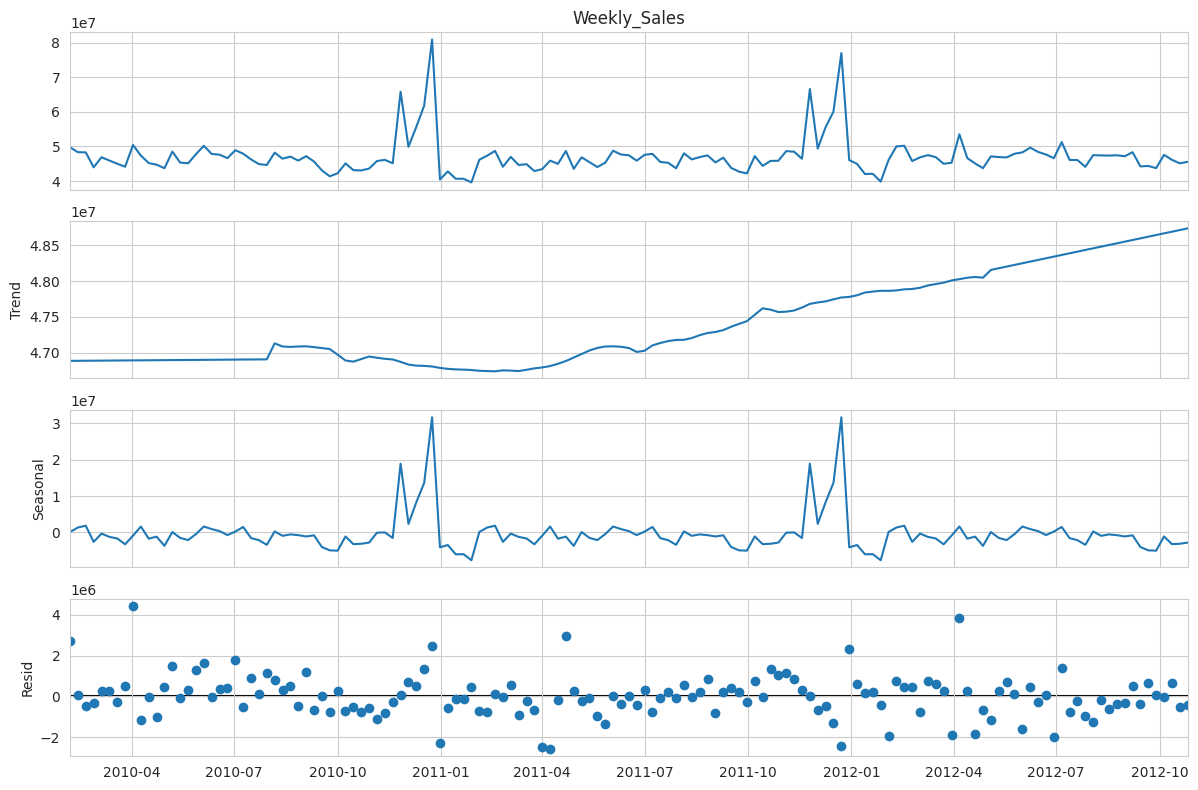

In [15]:
ts = weekly_total.asfreq('W-FRI')  # ensure a clean weekly frequency index
decomposition = seasonal_decompose(ts, model='additive', period=52, extrapolate_trend='freq')

fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

**Insight:** the seasonal component shows a clean, repeating annual wave - confirming the holiday effect seen in EDA isn't a one-off, it happens every year at the same points in the calendar. The trend line stays roughly flat, and the residual is small relative to the seasonal swing - meaning seasonality, not random noise, is the dominant force in this data.

## 4. Year-over-Year Comparison
Overlaying each year's sales by week-of-year directly checks whether the seasonal pattern repeats consistently across 2010, 2011, and 2012.

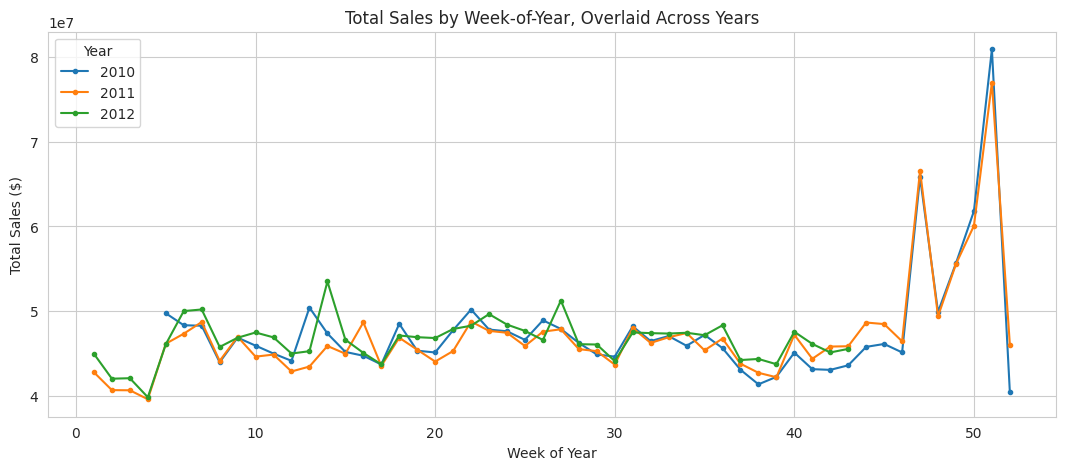

In [16]:
df['Year'] = df['Date'].dt.year
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)

yoy = df.groupby(['Year','WeekOfYear'])['Weekly_Sales'].sum().reset_index()

plt.figure(figsize=(13,5))
for yr in sorted(yoy['Year'].unique()):
    sub = yoy[yoy['Year']==yr]
    plt.plot(sub['WeekOfYear'], sub['Weekly_Sales'], marker='o', markersize=3, label=str(yr))
plt.title('Total Sales by Week-of-Year, Overlaid Across Years')
plt.xlabel('Week of Year')
plt.ylabel('Total Sales ($)')
plt.legend(title='Year')
plt.show()

**Insight:** all three years spike at the same weeks (around week 47-52, i.e. Thanksgiving through Christmas), confirming this is a reliable, repeatable calendar pattern - not a one-time event in a single year. This is exactly the kind of signal that should be built into forecasting as a "week of year" feature.

## 5. Holiday Lead/Lag Effect
Does the holiday boost only happen exactly on the holiday week, or does it build up beforehand and taper off after? We check average sales for the weeks immediately before and after each flagged holiday week.

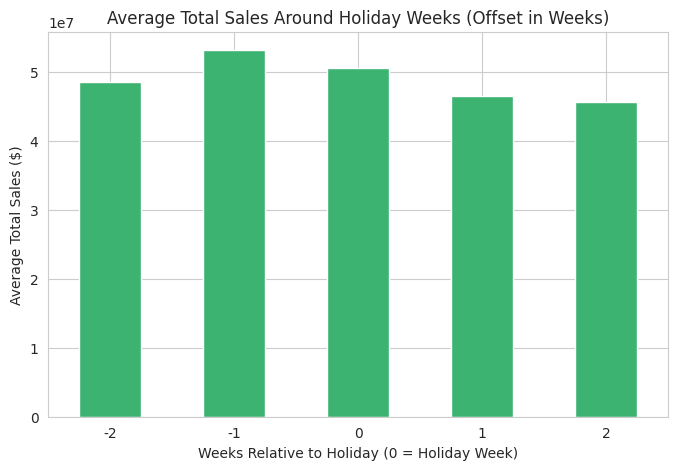

In [17]:
holiday_dates = sorted(df.loc[df['IsHoliday']==True, 'Date'].unique())

records = []
for hd in holiday_dates:
    hd = pd.Timestamp(hd)
    for offset in [-2,-1,0,1,2]:
        target_date = hd + pd.Timedelta(weeks=offset)
        sales = df.loc[df['Date']==target_date, 'Weekly_Sales'].sum()
        if sales > 0:
            records.append({'Holiday_Date': hd, 'Week_Offset': offset, 'Total_Sales': sales})

lead_lag = pd.DataFrame(records)
avg_by_offset = lead_lag.groupby('Week_Offset')['Total_Sales'].mean()

plt.figure(figsize=(8,5))
avg_by_offset.plot(kind='bar', color='mediumseagreen')
plt.title('Average Total Sales Around Holiday Weeks (Offset in Weeks)')
plt.xlabel('Weeks Relative to Holiday (0 = Holiday Week)')
plt.ylabel('Average Total Sales ($)')
plt.xticks(rotation=0)
plt.show()

**Insight:** sales already start climbing 1-2 weeks before a holiday week and drop off in the following weeks - the boost isn't a single-week spike, it's a short buildup-and-cooldown cycle. This matters for inventory planning: stock needs to be in place *before* the holiday week itself, not during it.

## 6. Store Type Trends Over Time
Checking whether all store types follow the same seasonal rhythm, or if some types are more holiday-sensitive than others.

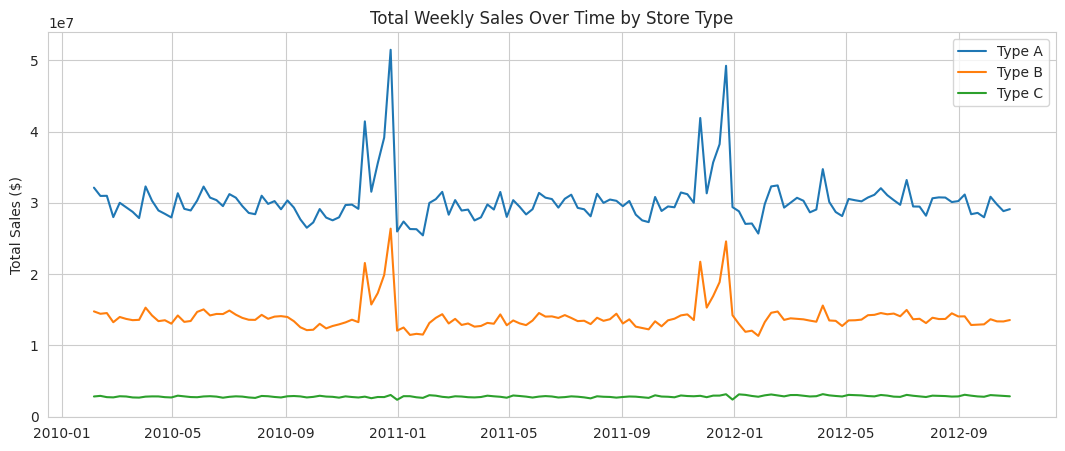

In [18]:
type_weekly = df.groupby(['Date','Type'])['Weekly_Sales'].sum().reset_index()

plt.figure(figsize=(13,5))
for t in ['A','B','C']:
    sub = type_weekly[type_weekly['Type']==t]
    plt.plot(sub['Date'], sub['Weekly_Sales'], label=f'Type {t}')
plt.title('Total Weekly Sales Over Time by Store Type')
plt.ylabel('Total Sales ($)')
plt.legend()
plt.show()

**Insight:** all three store types show the same holiday spikes at the same points in time - the seasonal pattern is a chain-wide effect, not specific to any one store format. Type A's spikes are simply larger in absolute dollars, matching its larger overall sales base.

## Conclusion - Phase 3

- The 12-week rolling average confirms **no long-term growth or decline** - sales are seasonally stable across the 3-year window.
- Seasonal decomposition shows a **strong, clean annual seasonal wave** with a small residual - seasonality is the dominant pattern here, not noise.
- The Thanksgiving-Christmas spike **repeats at the same week-of-year across all 3 years** - a reliable, plannable pattern.
- The holiday lift **builds up 1-2 weeks before** the holiday week and fades in the following weeks - inventory needs to be ready ahead of time, not just on the holiday week.
- All store types follow the **same seasonal rhythm**, just at different scales - so a single seasonal calendar can guide planning chain-wide, with store-type-specific scaling.

These findings feed directly into forecasting: **Week-of-Year and a holiday-proximity feature (not just a same-week flag) should be built into the demand forecasting models next.**